# MATH840 Final project: 48 hours of generation

**Artem Korniienko** · `KORNIIENKO_project.csv`

**Model:** the average of two gradient-boosting models (on $y$ and on $\log y$).
**Interval:** the forecast plus the 2.5% and 97.5% quantiles of the validation errors.

| | RMSE | MAPE | Winkler | coverage |
|---|---|---|---|---|
| seasonal naive | 269 | 153% | 2397 | 75% |
| my forecast | **243** | **123%** | **1171** | **92%** |

40 validation windows, Aug–Oct 2026. Code: `forecast.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

import forecast as F

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})
pd.set_option("display.width", 140, "display.precision", 2)
Path("figures").mkdir(exist_ok=True)

data, weather_fc = F.load_data()
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"forecast: {weather_fc['ds'].iloc[0]} to {weather_fc['ds'].iloc[-1]}")

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
forecast: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


## 1. What is in the series?

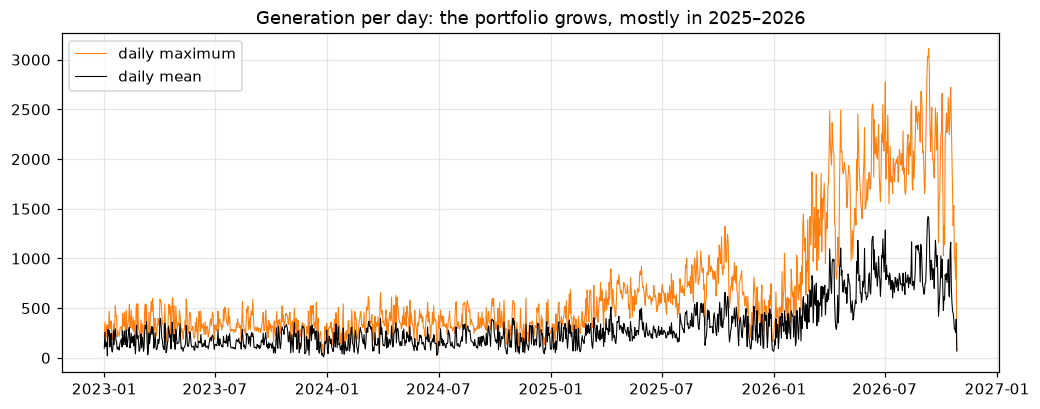

Mean y per year: {2023: 171.0, 2024: 184.0, 2025: 291.0, 2026: 684.0}


ds,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01,2025-01-01,2025-04-01,2025-07-01,2025-10-01,2026-01-01,2026-04-01,2026-07-01,2026-10-01
mean,162.0,208.0,152.0,204.0,145.0,191.0,168.0,193.0,214.0,303.0,247.0,413.0,308.0,718.0,794.0,675.0
p99,425.0,573.0,473.0,449.0,474.0,564.0,493.0,550.0,541.0,804.0,710.0,1232.0,849.0,2319.0,2318.0,2533.0


In [2]:
daily = data.set_index("ds")["y"].resample("D").agg(["mean", "max"])
fig, ax = plt.subplots()
ax.plot(daily.index, daily["max"], lw=0.7, color="tab:orange", label="daily maximum")
ax.plot(daily.index, daily["mean"], lw=0.7, color="black", label="daily mean")
ax.set_title("Generation per day: the portfolio grows, mostly in 2025–2026")
ax.legend()
fig.savefig("figures/series.png", bbox_inches="tight")
plt.show()

print("Mean y per year:", data.groupby(data.ds.dt.year)["y"].mean().round(0).to_dict())
monthly = data.set_index("ds")["y"].resample("MS").agg(["mean", lambda s: s.quantile(0.99)])
monthly.columns = ["mean", "p99"]
monthly.iloc[::3].T.round(0)

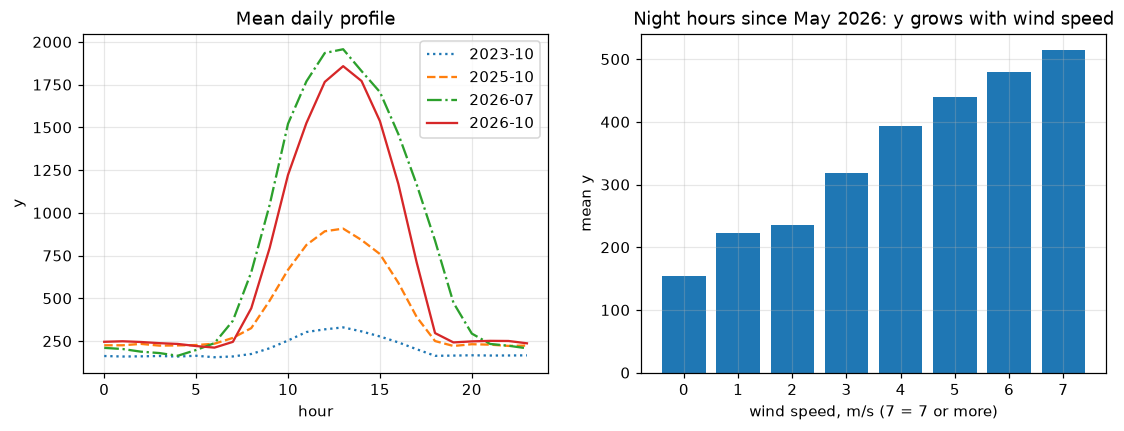

In [3]:
d = data.assign(hour=data["ds"].dt.hour, month=data["ds"].dt.month, year=data["ds"].dt.year)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (yr, mo), ls in [((2023, 10), ":"), ((2025, 10), "--"), ((2026, 7), "-."), ((2026, 10), "-")]:
    prof = d[(d.year == yr) & (d.month == mo)].groupby("hour")["y"].mean()
    axes[0].plot(prof.index, prof.values, ls=ls, label=f"{yr}-{mo:02d}")
axes[0].set(title="Mean daily profile", xlabel="hour", ylabel="y")
axes[0].legend()

recent = d[d.ds >= "2026-05-01"]
night = recent[recent.daylight == 0].groupby(recent.wind_speed.clip(upper=7))["y"].mean()
axes[1].bar(night.index, night.values, color="tab:blue")
axes[1].set(title="Night hours since May 2026: y grows with wind speed", xlabel="wind speed, m/s (7 = 7 or more)",
            ylabel="mean y")
fig.savefig("figures/profile_wind.png", bbox_inches="tight")
plt.show()

In [4]:
mid = d[(d.ds >= "2026-05-01") & d.hour.between(11, 14)]
print("Midday hours (11-14), May-Oct 2026: mean y and number of hours by cloud_cover")
display(mid.groupby("cloud_cover")["y"].agg(["mean", "count"]).round(0).T)
print("Correlation with y at midday:")
mid[["y", "cloud_cover", "temperature", "humidity", "wind_speed"]].corr()["y"].round(2).to_frame().T

Midday hours (11-14), May-Oct 2026: mean y and number of hours by cloud_cover


cloud_cover,0.00,0.25,0.50,0.75,1.00
mean,1007.0,1512.0,1657.0,1576.0,2016.0
count,15.0,155.0,59.0,1.0,486.0


Correlation with y at midday:


,y,cloud_cover,temperature,humidity,wind_speed
y,1.0,0.56,0.49,-0.62,0.39


In [5]:
# The daylight flag moves one hour earlier at the end of October every year (the clock change).
def daylight_window(day):
    hours = data.loc[(data.ds.dt.normalize() == day) & (data.daylight == 1), "ds"].dt.hour
    return f"{hours.min():02d}-{hours.max():02d}"

rows = {str(day.date()): daylight_window(day) for day in pd.to_datetime(
    ["2025-10-25", "2025-10-26", "2025-10-27", "2025-10-28", "2026-10-25", "2026-10-26"])}
rows["2026-10-27 (forecast)"] = "{:02d}-{:02d}".format(*weather_fc.loc[weather_fc.daylight == 1, "ds"].dt.hour.agg(["min", "max"]))
pd.Series(rows, name="daylight hours").to_frame().T

,2025-10-25,2025-10-26,2025-10-27,2025-10-28,2026-10-25,2026-10-26,2026-10-27 (forecast)
daylight hours,08-16,08-16,07-15,07-15,08-16,08-16,07-15


In [6]:
# How noisy is the weather forecast? Compare its hour-to-hour changes with those of the actual weather.
# If the forecast is the actual weather plus independent noise e, then Var(diff fc) = Var(diff actual) + 2 Var(e).
rough = {}
for col in ["temperature", "pressure", "wind_speed", "humidity", "air_density", "cloud_cover"]:
    va = data[col].diff().var()
    v1, v2 = weather_fc[col].iloc[:24].diff().var(), weather_fc[col].iloc[24:].diff().var()
    rough[col] = {"sd diff actual": np.sqrt(va), "sd diff fc day 1": np.sqrt(v1), "sd diff fc day 2": np.sqrt(v2),
                  "implied noise sd day 1": np.sqrt(max(v1 - va, 0) / 2), "implied noise sd day 2": np.sqrt(max(v2 - va, 0) / 2),
                  "noise used, day 1": F.NOISE.get(col, (np.nan, np.nan))[0], "noise used, day 2": F.NOISE.get(col, (np.nan, np.nan))[1]}
pd.DataFrame(rough).T.round(3)

,sd diff actual,sd diff fc day 1,sd diff fc day 2,implied noise sd day 1,implied noise sd day 2,"noise used, day 1","noise used, day 2"
temperature,1.37e+00,2.00,3.51,1.03,2.28,1.00,2.30
pressure,5.21e-01,0.60,2.57,0.21,1.78,0.30,1.80
wind_speed,1.19e+00,0.56,1.25,0.00,0.28,0.50,0.50
humidity,6.40e+00,2.22,6.76,0.00,1.54,3.00,3.00
air_density,6.00e-03,0.01,0.02,0.01,0.01,0.01,0.01
cloud_cover,2.23e-01,0.13,0.32,0.00,0.16,NaN,NaN


* Mean $y$ grew from 171 (2023) to 684 (2026), so last week's level is a feature.
* Solar by day, wind at night, so the hour and the day of year are features.
* `cloud_cover` has the opposite sign to its label, so the model learns the signs from the data.
* `daylight` shifts one hour earlier from 27 Oct.
* The weather forecast is noisy, so validation adds the same noise.

I use the weather forecast: without it the model loses to the benchmark.

## 2. How did I check the forecast before submitting it?

In [7]:
VAL = Path("results/validation.csv")
if VAL.exists():
    val = pd.read_csv(VAL, parse_dates=["origin", "ds"])
else:                                    # about 9 minutes
    val = F.run_validation(data, F.validation_origins(data))
    VAL.parent.mkdir(exist_ok=True)
    val.to_csv(VAL, index=False)
print(f"{val.origin.nunique()} windows of 48 hours, origins from {val.origin.min()} to {val.origin.max()}")

methods = ["snaive", "profile7", "gbm_no_weather", "gbm_actual_weather", "gbm", "gbm_log", "ensemble"]
results = F.point_scores(val, methods)
results["RMSE skill vs snaive"] = results["RMSE"] / results.loc["snaive", "RMSE"]
results

40 windows of 48 hours, origins from 2026-08-08 00:00:00 to 2026-10-25 00:00:00


,RMSE,MAPE,RMSE skill vs snaive
snaive,268.66,153.29,1.00
profile7,307.46,225.96,1.14
gbm_no_weather,285.10,218.04,1.06
gbm_actual_weather,228.41,142.60,0.85
gbm,234.55,149.44,0.87
gbm_log,263.59,96.98,0.98
ensemble,243.00,122.52,0.90


In [8]:
by_day = {}
for day, (a, b) in {"day 1 (public)": (1, 24), "day 2 (private)": (25, 48)}.items():
    s = F.point_scores(val[val.step.between(a, b)], ["snaive", "gbm", "gbm_log", "ensemble"])
    by_day[day] = s.stack()
pd.DataFrame(by_day).unstack(level=1).round(1)

day 1 (public)        day 2 (private)       
                   RMSE   MAPE            RMSE   MAPE
snaive            237.5  181.6           284.4  125.0
gbm               230.4  211.2           229.8   87.7
gbm_log           262.1  127.1           253.2   66.9
ensemble          240.1  168.4           235.5   76.6

the ensemble has the lower RMSE in 62% of the windows


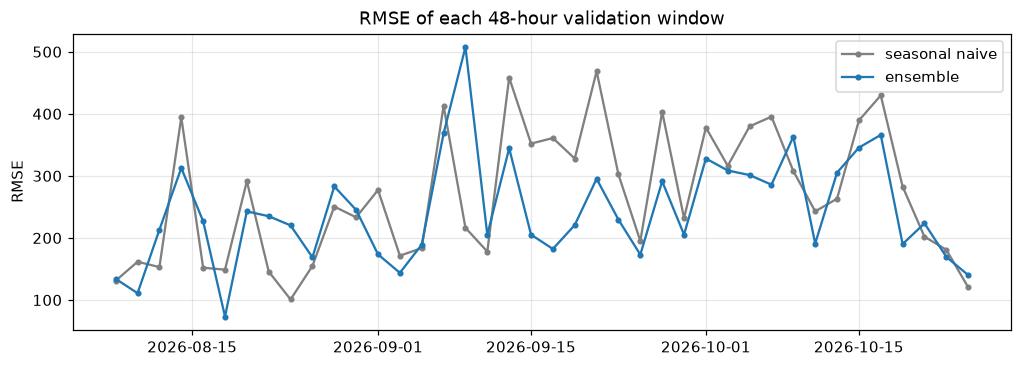

In [9]:
w = pd.DataFrame({"snaive": F.window_scores(val, "snaive")["RMSE"],
                  "ensemble": F.window_scores(val, "ensemble")["RMSE"]})
print(f"the ensemble has the lower RMSE in {(w.ensemble < w.snaive).mean():.0%} of the windows")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(w.index, w.snaive, "o-", ms=3, color="grey", label="seasonal naive")
ax.plot(w.index, w.ensemble, "o-", ms=3, color="tab:blue", label="ensemble")
ax.set(title="RMSE of each 48-hour validation window", ylabel="RMSE")
ax.legend()
fig.savefig("figures/windows.png", bbox_inches="tight")
plt.show()

40 windows of 48 hours (8 Aug – 25 Oct 2026), refitted each time, with simulated weather-forecast errors.

* Ensemble vs benchmark: RMSE 243 vs 269, MAPE 123% vs 153%.
* Without weather: RMSE 285, worse than the benchmark.
* The $y$ model has the best RMSE, the $\log y$ model the best MAPE, so I average them.
* Day 2, which decides the ranking: RMSE 235 vs 284.

## 3. How good is the interval?

In [10]:
q = F.interval_quantiles(val, "ensemble")
print("2.5% and 97.5% quantiles of actual - forecast, all 40 windows (used for the final interval):")
display(q.round(0))

print("Calibrated on the first 20 windows, scored on the last 20:")
check = F.interval_check(val, "ensemble", n_cal=20)
check

2.5% and 97.5% quantiles of actual - forecast, all 40 windows (used for the final interval):


0.03   0.97
day daylight              
1   0        -278.0  503.0
    1        -508.0  712.0
2   0        -263.0  522.0
    1        -494.0  650.0

Calibrated on the first 20 windows, scored on the last 20:


,RMSE,MAPE,Winkler,coverage
ensemble,255.80,192.78,1170.91,0.92
snaive,308.92,249.00,2396.70,0.75


In [11]:
# The alternative I tried: quantiles of log(actual / forecast), so the interval scales with the level.
origins = sorted(val.origin.unique())
cal, test = val[val.origin.isin(origins[:20])], val[val.origin.isin(origins[20:])].copy()
r = cal.assign(r=np.log(cal.y / cal.ensemble), day=np.where(cal.step > 24, 2, 1))
qm = r.groupby(["day", "daylight"])["r"].quantile([0.025, 0.975]).unstack()
keys = list(zip(np.where(test.step > 24, 2, 1), test.daylight))
test["lo"] = test.ensemble * np.exp([qm.loc[k, 0.025] for k in keys])
test["hi"] = test.ensemble * np.exp([qm.loc[k, 0.975] for k in keys])
multiplicative = F.window_scores(test, "ensemble", "lo", "hi").mean()
print("multipliers of the forecast:")
display(np.exp(qm).round(2))
pd.DataFrame({"additive (chosen)": check.loc["ensemble"], "multiplicative": multiplicative,
              "seasonal naive": check.loc["snaive"]}).T[["Winkler", "coverage"]]

multipliers of the forecast:


0.03  0.97
day daylight            
1   0         0.14  4.38
    1         0.58  1.67
2   0         0.20  3.52
    1         0.63  1.73

,Winkler,coverage
additive (chosen),1170.91,0.92
multiplicative,1391.96,0.90
seasonal naive,2396.70,0.75


The interval is the forecast plus the 2.5% and 97.5% error quantiles, by day 1/2 and day/night. The lower bound is at least 0.

Calibrated on the first 20 windows and tested on the last 20: coverage 92%, Winkler 1171 (benchmark: 75%, 2397).
A multiplicative version ($\log(y/\hat y)$) did worse: Winkler 1392, coverage 90%.

## 4. What is left, and what did not work?

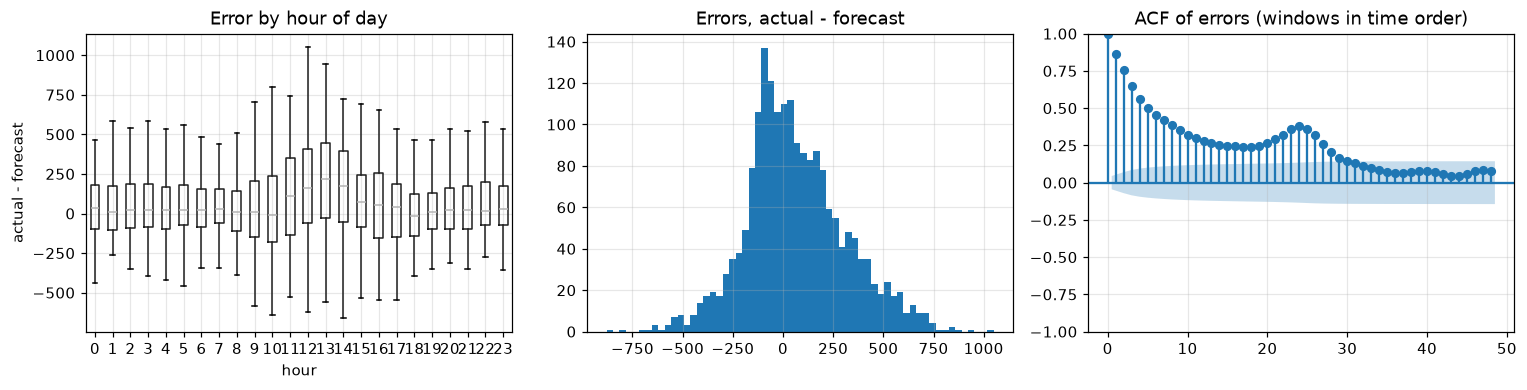

mean error by forecast day: {1: 61.0, 2: 66.2}
mean error, night (0) vs daylight (1): {0: 50.4, 1: 77.8}
median error at 11-14: 159.3


In [12]:
res = val.assign(err=val.y - val.ensemble, hour=val.ds.dt.hour)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
res.boxplot(column="err", by="hour", ax=axes[0], showfliers=False)
axes[0].set(title="Error by hour of day", xlabel="hour", ylabel="actual - forecast")
axes[1].hist(res.err, bins=60, color="tab:blue")
axes[1].set(title="Errors, actual - forecast")
stacked = res.sort_values(["origin", "step"])["err"].to_numpy()
plot_acf(stacked, lags=48, ax=axes[2], title="ACF of errors (windows in time order)")
plt.suptitle("")
fig.tight_layout()
fig.savefig("figures/residuals.png", bbox_inches="tight")
plt.show()

print("mean error by forecast day:", res.groupby(np.where(res.step > 24, 2, 1))["err"].mean().round(1).to_dict())
print("mean error, night (0) vs daylight (1):", res.groupby("daylight")["err"].mean().round(1).to_dict())
print("median error at 11-14:", res[res.hour.between(11, 14)]["err"].median().round(1))

In [13]:
# A bias correction I tried and dropped: add the mean error of the first 20 windows to the last 20.
bias = (cal.y - cal.ensemble).mean()
test["ensemble_plus_bias"] = test.ensemble + bias
print(f"mean error on the first 20 windows: {bias:.1f}")
F.point_scores(test, ["snaive", "ensemble", "ensemble_plus_bias"])

mean error on the first 20 windows: 77.9


,RMSE,MAPE
snaive,308.92,249.00
ensemble,255.80,192.78
ensemble_plus_bias,254.73,297.88


* The forecast is about 60 too low on average, most of all at midday.
* The errors are largest at 9–14 and are autocorrelated within the day.

**Dropped:** the mean of the last 7 days (RMSE 307), the model without weather (285), the multiplicative interval,
and a bias correction (MAPE 193% → 298%).

**Next:** separate solar and wind models, and quantile regression for the interval.

## 5. The final forecast

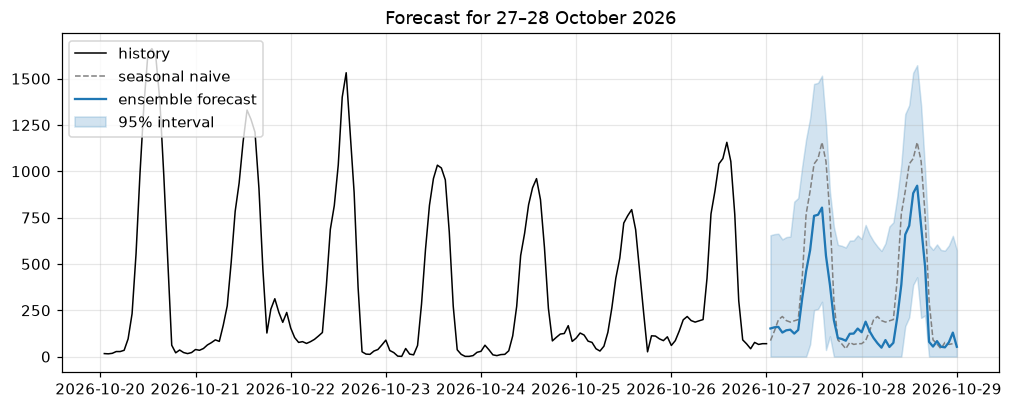

saved KORNIIENKO_project.csv


,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,151.9,0.0,654.7
1,2026-10-27 02:00:00,158.2,0.0,661.0
2,2026-10-27 03:00:00,160.4,0.0,663.1
3,2026-10-27 04:00:00,129.9,0.0,632.7
4,2026-10-27 05:00:00,142.1,0.0,644.9
5,2026-10-27 06:00:00,145.2,0.0,648.0
6,2026-10-27 07:00:00,124.4,0.0,836.1
7,2026-10-27 08:00:00,144.1,0.0,855.7
8,2026-10-27 09:00:00,313.7,0.0,1025.3
9,2026-10-27 10:00:00,462.3,0.0,1173.9


In [14]:
submission = F.final_forecast(data, weather_fc, val)
forecast, lower_95, upper_95 = (submission[c].to_numpy() for c in ["forecast", "lower_95", "upper_95"])
bench = F.snaive(data["y"].to_numpy())
FUTURE = weather_fc["ds"]

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * 24:], data["y"].iloc[-7 * 24:], color="black", lw=1, label="history")
ax.plot(FUTURE, bench[0], color="grey", ls="--", lw=1, label="seasonal naive")
ax.plot(FUTURE, forecast, color="tab:blue", label="ensemble forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend(loc="upper left")
ax.set_title("Forecast for 27–28 October 2026")
fig.savefig("figures/forecast.png", bbox_inches="tight")
plt.show()

FILE = f"{F.SURNAME}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)
submission.round(1)

Day 1 is humid (94–100%), with a peak of about 800. Day 2 is drier, with a peak of about 920. Nights are 50–190.